-   1.复盘
    -   1.1
        -   1.1.1 昨天（11/2）学了什么？今天和它是什么关系？
            -   昨天将11.1的空转的小CNN接入到了训练循环，跑出train 79.74% / val 76.60%，并且将权重，配置，曲线存盘。今天要做的是，保存下来的东西，换个干净的环境也能原样加载和评价，并且将它与线性baseline放在同一张表对比。
        -   1.1.2 今天这块在整条项目链的哪个位置？
            -   数据→张量→卷积特征→Flatten→Linear→10类分数→前向→损失→梯度清零→反向传播→参数更新→评价→【今天：保存→独立加载→复用评价】→部署/换数据
        -   1.1.3 今天学完，我能多做哪一件具体的事？
            -   不看讲义，能：
                -   ① 在一个新进程/新 kernel里把 model_weights.pt 加载出来，完整评价验证集，得到与训练时一致的 val 76.60%；
                -   ② 说出「为什么必须重新定义一模一样的模型结构」「weights_only=True 是干嘛的」；
                -   ③ 把线性、CNN 两条曲线画在一张图上并读出三条结论。
    -   1.2
        -   1.2.1 训练循环五步的顺序，各一句话？
            -   前向算分数→算损失→清零梯度→反向算梯度→优化器更新参数
        -   1.2.2 为什么评价时要 model.eval()＋torch.no_grad()，它俩是一回事吗？
            -   不是，model.eval是切换行为(避免BatchNorm和Dropout)，torch.no_grad不记录梯度，节省内存，加快执行
        -   1.2.3  频谱泄漏是什么引起的？怎么减轻？
            -   信号频率不落在fs/N的格子上，会被摊到相邻得到格点，减轻方法是拉长观察时间（今天完成）或加窗

-   ------------------------

-   2.CNN独立加载评价&同条件对比表

-   2.1
    -   model_weights.pt 里只存了参数表，没有代码。要加载，必须先"照着训练时的样子把骨架再搭一遍"，层名、顺序、参数完全一致，否则 load_state_dict 会对不上。


-   2.2 独立加载评价

In [ ]:
#导入 + 重新定义 SmallCNN
from pathlib import Path
import json
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 8, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(8, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(16 * 7 * 7, 10),
        )
    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

print("导入和类定义完成")




导入和类定义完成


In [2]:
#准备数据（⚠️ 关键：验证集用 train_full）
data_root = Path(r"E:\develop\Graduate_AI\learning-lab\data")
tf = transforms.ToTensor()

train_full = datasets.FashionMNIST(data_root, train=True, download=False, transform=tf)

split = json.loads(Path(r"E:\develop\Graduate_AI\learning-lab\results\day22\split_indices.json").read_text(encoding="utf-8"))
val_set = Subset(train_full, split["val_indices"][:1000])   # ✅ 用 train_full，不是 test_full
val_loader = DataLoader(val_set, batch_size=64, shuffle=False, num_workers=0)

print("验证集样本数：", len(val_set))


验证集样本数： 1000


In [3]:
#独立加载权重
run_dir = Path(r"E:\develop\Graduate_AI\learning-lab\results\day1102\20261102_170336")

model = SmallCNN()
state = torch.load(run_dir / "model_weights.pt", map_location="cpu", weights_only=True)
model.load_state_dict(state)
model.eval()

print("权重加载成功，参数量：", sum(p.numel() for p in model.parameters()))


权重加载成功，参数量： 9098


In [5]:
#写 evaluate 并完整评价验证集
def evaluate(model,loader):
    model.eval()
    total_loss,correct,n=0.,0,0
    with torch.no_grad():
        for xb,yb in loader:
            z=model(xb)
            total_loss+=nn.functional.cross_entropy(z,yb).item()*yb.size(0)
            correct+=(z.argmax(dim=1)==yb).sum().item()
            n+=yb.size(0)

    return total_loss/n,correct/n

va_loss,va_acc=evaluate(model,val_loader)
print(f"加载后验证：val_loss={va_loss:.4f}  val_acc={va_acc:.4f}")

加载后验证：val_loss=0.6855  val_acc=0.7660


In [6]:
#predict：抽 3 张验证图，打印 argmax + softmax 概率
class_names = train_full.classes
xb, yb = next(iter(DataLoader(val_set, batch_size=3, shuffle=False, num_workers=0)))
with torch.no_grad():
    prob = model(xb).softmax(dim=1)
    pred = prob.argmax(dim=1)
for i in range(len(yb)):
    print(f"真实 {class_names[yb[i].item()]:<12s} → 预测 {class_names[pred[i].item()]:<12s} 置信度 {prob[i, pred[i]].item():.3f}")


真实 Shirt        → 预测 Shirt        置信度 0.430
真实 Trouser      → 预测 Dress        置信度 0.893
真实 Bag          → 预测 Bag          置信度 0.974


In [ ]:
#价结果和 batch 大小无关吗？

# 预测，
for bs in (64, 32, 1):
    loader = DataLoader(val_set, batch_size=bs, shuffle=False, num_workers=0)
    l, a = evaluate(model, loader)
    print(f"batch={bs:>3d}  val_loss={l:.6f}  val_acc={a:.6f}")


    #evaluate 里 loss 是 loss * yb.size(0) 按样本数加权、acc 是 correct/n 按样本数平均，都不按批平均，所以最后一批是否凑满 64 不影响结果。

batch= 64  val_loss=0.685470  val_acc=0.766000
batch= 32  val_loss=0.685470  val_acc=0.766000
batch=  1  val_loss=0.685470  val_acc=0.766000


-   2.4对比表
    -   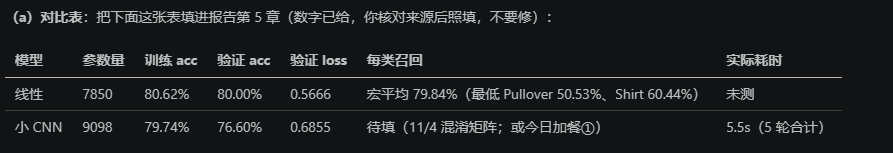
    -   小 CNN(9098) 验证 76.60% < 线性(7850) 80.00%；训练 79.74% < 80.62%。单次 5 轮只支持「本配置下的观察」，不能推出「CNN 不如线性」的普遍结论。耗时也不直接可比：线性未同条件计时、CNN 的 5.5s 是 5 轮合计。

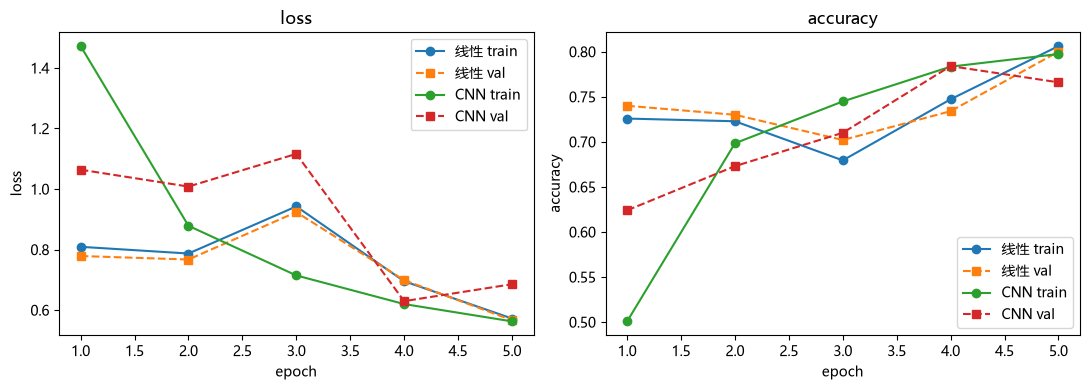

In [9]:
import json
from pathlib import Path
import matplotlib.pyplot as plt
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

lin = json.loads(Path(r"E:\develop\Graduate_AI\learning-lab\results\day23\20261023_142120_980030\history.json").read_text(encoding="utf-8"))
cnn = json.loads(Path(r"E:\develop\Graduate_AI\learning-lab\results\day1102\20261102_170336\history.json").read_text(encoding="utf-8"))

eps = [h["epoch"] for h in cnn]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, trk, vak, title in [
    (axes[0], "train_loss", "val_loss", "loss"),
    (axes[1], "train_accuracy", "val_accuracy", "accuracy"),
]:
    ax.plot(eps, [h[trk] for h in lin], "o-",  label="线性 train")
    ax.plot(eps, [h[vak] for h in lin], "s--", label="线性 val")
    ax.plot(eps, [h[trk] for h in cnn], "o-",  label="CNN train")
    ax.plot(eps, [h[vak] for h in cnn], "s--", label="CNN val")
    ax.set_xlabel("epoch"); ax.set_ylabel(title); ax.legend(); ax.set_title(title)
fig.tight_layout()
out = Path(r"E:\develop\Graduate_AI\learning-lab\results\day1103")
out.mkdir(exist_ok=True)
fig.savefig(out / "linear_vs_cnn_overlay.png", dpi=120)
plt.show()


-   1.线性第一轮val就到74%，CNN第一轮val只有62.4%——CNN前几轮收敛更慢（是卷积网络+lr=0.1在本配置下的正常现象）
-   2.线性第三轮loss有明显上调，是正常跳动；在第五轮cnn的train更平滑，但是val有上升，是轻微的过拟合现象
-   3.两条val曲线重点：线性80%大于CNN76.6%

-   2.5小测
    -   加载权重前，为什么必须重新定义和训练时一模一样的 SmallCNN？
        -   因为torch.save存的是层名→参数表，不含代码，所以要重新定义和训练
    -   加载后完整评价，val_acc 应等于 history.json 里哪个数？为什么？
        -   第五轮val_acc 76.6% 保存的是无论结束时候的权重
    -   eval()、no_grad()、load_state_dict() 是三件事吗？各管什么？
        -   eval是切层行为，no_grad()不记录梯度省内存，load_state_dict将权重填回模型